# PyHF Tutorial: Hartree-Fock Calculations in Python

This notebook demonstrates the capabilities and usage of PyHF, a Python library for performing Hartree-Fock quantum chemistry calculations.

In [1]:
#Imports
import sys
sys.path.insert(0, '..')

import numpy as np
import matplotlib.pyplot as plt

from pyhf.molecule import Atom, Molecule
from pyhf.integrals import compute_integrals
from pyhf.scf import RHF
from pyhf.analysis import (
    print_energy_decomposition,
    MullikenPopulation,
    print_koopmans_analysis
)
from pyhf.analysis.energy import decompose_energy, virial_ratio
from pyhf.analysis.koopmans import ionization_energy, electron_affinity, homo_lumo_gap
from pyhf.utils.constants import HARTREE_TO_EV, BOHR_TO_ANGSTROM

/home/pgclark/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


## Basic H_2 Calculation

Start with one hydrogen molecule using Restricted-Hartree-Fock, RHF.

In [2]:
# Bond length is 1.4 bohr ~ 0.74 angstrom
h2 = Molecule([Atom('H', [0, 0, 0]), Atom('H', [0, 0, 1.4])])
print(h2)

Molecule: 2 atoms, 2 electrons
Charge: 0, multiplicity: 1

Atom coordinates (Bohr):
Atom          X              Y              Z
H       0.000000      0.000000      0.000000
H       0.000000      0.000000      1.400000


In [3]:
# Compute one- and two-electron integrals
integrals, basis_to_atom = compute_integrals(h2)

print(f"Number of basis functions: {integrals['S'].shape[0]}")
print(f"\nOverlap matrix (S):")
print(integrals['S'])

Number of basis functions: 2

Overlap matrix (S):
[[0.99999999 0.6593182 ]
 [0.6593182  0.99999999]]


In [4]:
# Run RHF calculation
rhf = RHF(h2, integrals)
energy = rhf.run(use_diis=True)

print(f"SCF converged in {rhf.scf_iterations} iterations")
print(f"Total energy: {energy:.6f} hartree")
print(f"Expected: -1.116700 hartree")

SCF converged in 2 iterations
Total energy: -1.116714 hartree
Expected: -1.116700 hartree


## Energy decomposition

Breaking down the total energy into the various components

In [5]:
# Get energy components
components = decompose_energy(rhf)
print_energy_decomposition(rhf)
print(f"\nVirial ratio (-V/T): {virial_ratio(rhf):.6f}")

Kinetic: 1.2010794986, Nuclear attraction: -3.7066736223
One-electron: -2.5055941237, Two-electron: 0.6745940843
Electronic: -1.8310000393, Nuclear repulsion: 0.7142857143, Total: -1.1167143251

Virial ratio (-V/T): 1.929759


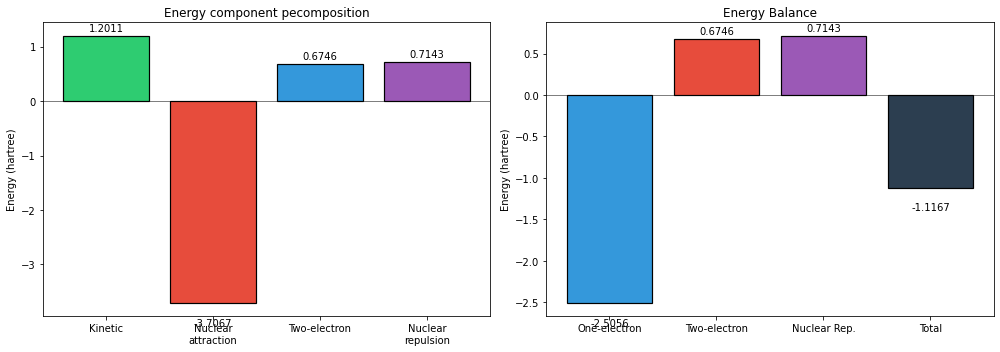

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

labels = ['Kinetic', 'Nuclear\nattraction', 'Two-electron', 'Nuclear\nrepulsion']
values = [
    components['kinetic'],
    components['nuclear_attraction'],
    components['two_electron'],
    components['nuclear_repulsion']
]
colors = ['#2ecc71', '#e74c3c', '#3498db', '#9b59b6']

bars = ax1.bar(labels, values, color=colors, edgecolor='black', linewidth=1.2)
ax1.axhline(y=0, color='black', linestyle='-', linewidth=0.5)
ax1.set_ylabel('Energy (hartree)')
ax1.set_title('Energy component pecomposition')

for bar, val in zip(bars, values):
    height = bar.get_height()
    ax1.annotate(f'{val:.4f}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3 if height > 0 else -15),
                textcoords="offset points",
                ha='center', va='bottom' if height > 0 else 'top',
                fontsize=10)

balance_labels = ['One-electron', 'Two-electron', 'Nuclear Rep.', 'Total']
balance_values = [
    components['one_electron'],
    components['two_electron'],
    components['nuclear_repulsion'],
    components['total']
]
balance_colors = ['#3498db', '#e74c3c', '#9b59b6', '#2c3e50']

bars2 = ax2.bar(balance_labels, balance_values, color=balance_colors, edgecolor='black', linewidth=1.2)
ax2.axhline(y=0, color='black', linestyle='-', linewidth=0.5)
ax2.set_ylabel('Energy (hartree)')
ax2.set_title('Energy Balance')

for bar, val in zip(bars2, balance_values):
    height = bar.get_height()
    ax2.annotate(f'{val:.4f}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3 if height > 0 else -15),
                textcoords="offset points",
                ha='center', va='bottom' if height > 0 else 'top',
                fontsize=10)

plt.tight_layout()
plt.show()

## Molecular orbital analysis

Koopmans' theorem relates orbital energies to ionization potentials and electron affinities.

In [7]:
mo = rhf.get_molecular_orbitals()
print_koopmans_analysis(rhf)

print("\nMolecular orbital coefficients:")
for i in range(rhf.n_basis):
    occ = "occ" if mo['occupations'][i] > 0 else "vir"
    coeffs = mo['coefficients'][:, i]
    print(f"MO {i+1} ({occ}): E = {mo['energies'][i]:.6f} Ha, coeffs = [{coeffs[0]:.4f}, {coeffs[1]:.4f}]")

IE(HOMO): 0.578203 Ha (15.7337 eV), EA(LUMO): -0.670268 Ha (-18.2389 eV), Gap: 1.248471 Ha
MO 1 (occ): -0.578203 Ha (-15.7337 eV)
MO 2 (vir): 0.670268 Ha (18.2389 eV)

Molecular orbital coefficients:
MO 1 (occ): E = -0.578203 Ha, coeffs = [-0.5489, -0.5489]
MO 2 (vir): E = 0.670268 Ha, coeffs = [-1.2115, 1.2115]


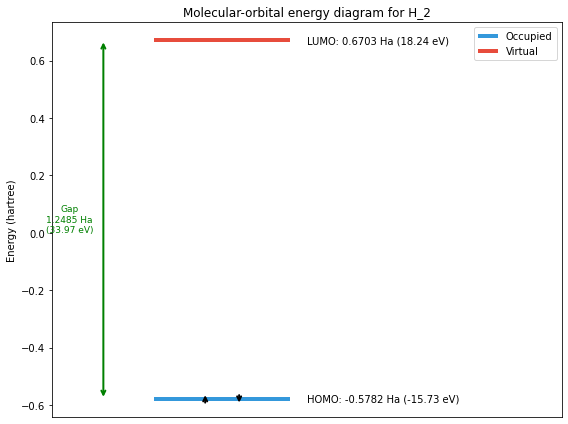

In [8]:
fig, ax = plt.subplots(figsize=(8, 6))

energies = mo['energies']
occupations = mo['occupations']
n_occ = rhf.n_occ

# Draw orbital energy levels
for i, (e, occ) in enumerate(zip(energies, occupations)):
    color = '#3498db' if occ > 0 else '#e74c3c'
    label = 'Occupied' if i == 0 else ('Virtual' if i == n_occ else None)
    ax.hlines(e, 0.3, 0.7, colors=color, linewidth=4, label=label)
    
    orbital_name = 'HOMO' if i == n_occ - 1 else ('LUMO' if i == n_occ else f'MO{i+1}')
    ax.text(0.75, e, f'{orbital_name}: {e:.4f} Ha ({e*HARTREE_TO_EV:.2f} eV)',
           va='center', fontsize=10)
    
    if occ > 0:
        ax.annotate('', xy=(0.45, e+0.02), xytext=(0.45, e-0.02),
                   arrowprops=dict(arrowstyle='->', color='black', lw=2))
        ax.annotate('', xy=(0.55, e-0.02), xytext=(0.55, e+0.02),
                   arrowprops=dict(arrowstyle='->', color='black', lw=2))

# Draw HOMO-LUMO gap
gap = homo_lumo_gap(rhf)
homo_e = energies[n_occ - 1]
lumo_e = energies[n_occ]
ax.annotate('', xy=(0.15, lumo_e), xytext=(0.15, homo_e),
           arrowprops=dict(arrowstyle='<->', color='green', lw=2))
ax.text(0.05, (homo_e + lumo_e)/2, f'Gap\n{gap:.4f} Ha\n({gap*HARTREE_TO_EV:.2f} eV)',
       va='center', ha='center', fontsize=9, color='green')

ax.set_xlim(0, 1.5)
ax.set_ylabel('Energy (hartree)')
ax.set_title('Molecular-orbital energy diagram for H_2')
ax.set_xticks([])
ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

## Potential energy surface scan

Computing energy variation based on bond distance

In [9]:
# Bond distances from 0.8 to 5.0 bohr
distances = np.linspace(0.8, 5.0, 30)
energies = []
kinetic_energies = []
potential_energies = []

for r in distances:
    mol = Molecule([Atom('H', [0, 0, 0]), Atom('H', [0, 0, r])])
    ints, _ = compute_integrals(mol)
    rhf = RHF(mol, ints)
    try:
        rhf.run(use_diis=True)
        energies.append(rhf.energy)
        comp = decompose_energy(rhf)
        kinetic_energies.append(comp['kinetic'])
        potential_energies.append(comp['nuclear_attraction'] + comp['two_electron'] + comp['nuclear_repulsion'])
    except RuntimeError:
        energies.append(np.nan)
        kinetic_energies.append(np.nan)
        potential_energies.append(np.nan)

energies = np.array(energies)
kinetic_energies = np.array(kinetic_energies)
potential_energies = np.array(potential_energies)

In [10]:
# Find equilibrium geometry
valid_mask = ~np.isnan(energies)
min_idx = np.nanargmin(energies)
r_eq = distances[min_idx]
e_min = energies[min_idx]

print(f"Equilibrium bond length: {r_eq:.3f} bohr = ({r_eq * BOHR_TO_ANGSTROM:.3f} angstrom)")
print(f"Minimum energy: {e_min:.6f} hartree")

Equilibrium bond length: 1.379 bohr = (0.730 angstrom)
Minimum energy: -1.117198 hartree


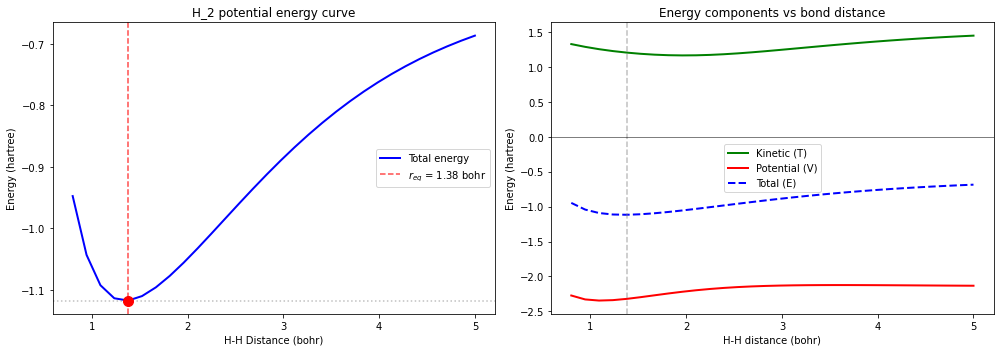

In [11]:
# Plot potential energy surface
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left: Total energy curve
ax1.plot(distances[valid_mask], energies[valid_mask], 'b-', linewidth=2, label='Total energy')
ax1.axvline(x=r_eq, color='red', linestyle='--', alpha=0.7, label=f'$r_{{eq}}$ = {r_eq:.2f} bohr')
ax1.axhline(y=e_min, color='gray', linestyle=':', alpha=0.5)
ax1.scatter([r_eq], [e_min], color='red', s=100, zorder=5)

ax1.set_xlabel('H-H Distance (bohr)')
ax1.set_ylabel('Energy (hartree)')
ax1.set_title('H_2 potential energy curve')
ax1.legend()

# Right: Energy components
ax2.plot(distances[valid_mask], kinetic_energies[valid_mask], 'g-', linewidth=2, label='Kinetic (T)')
ax2.plot(distances[valid_mask], potential_energies[valid_mask], 'r-', linewidth=2, label='Potential (V)')
ax2.plot(distances[valid_mask], energies[valid_mask], 'b--', linewidth=2, label='Total (E)')
ax2.axvline(x=r_eq, color='gray', linestyle='--', alpha=0.5)
ax2.axhline(y=0, color='black', linestyle='-', linewidth=0.5)

ax2.set_xlabel('H-H distance (bohr)')
ax2.set_ylabel('Energy (hartree)')
ax2.set_title('Energy components vs bond distance')
ax2.legend()

plt.tight_layout()
plt.show()

## Comparing molecules

Comparing properties across various types of hydrogen-like anions.

In [12]:
molecules_data = {
    'H2': {'atoms': [('H', 0), ('H', 1.4)], 'basis_map': [0, 1]},
    'HeH+': {'atoms': [('He', 0), ('H', 1.5)], 'basis_map': [0, 1], 'charge': 1},
    'LiH': {'atoms': [('Li', 0), ('H', 3.0)], 'basis_map': [0, 0, 0, 0, 0, 1]},
}

results = {}

for name, data in molecules_data.items():
    atoms = [Atom(sym, [0, 0, z]) for sym, z in data['atoms']]
    charge = data.get('charge', 0)
    mol = Molecule(atoms, charge=charge)
    
    ints, _ = compute_integrals(mol)
    rhf = RHF(mol, ints)
    
    try:
        rhf.run(use_diis=True)
        comp = decompose_energy(rhf)
        
        results[name] = {
            'energy': rhf.energy,
            'iterations': rhf.scf_iterations,
            'n_electrons': mol.n_electrons,
            'virial': virial_ratio(rhf),
            'homo': rhf.orbital_energies[rhf.n_occ - 1],
            'gap': homo_lumo_gap(rhf) if rhf.n_basis > rhf.n_occ else None
        }
        print(f"{name}: E = {rhf.energy:.6f} Ha, {rhf.scf_iterations} iterations")
    except Exception as e:
        print(f"{name}: Failed - {e}")

H2: E = -1.116714 Ha, 2 iterations
HeH+: E = -2.845278 Ha, 14 iterations
LiH: E = -7.804354 Ha, 7 iterations


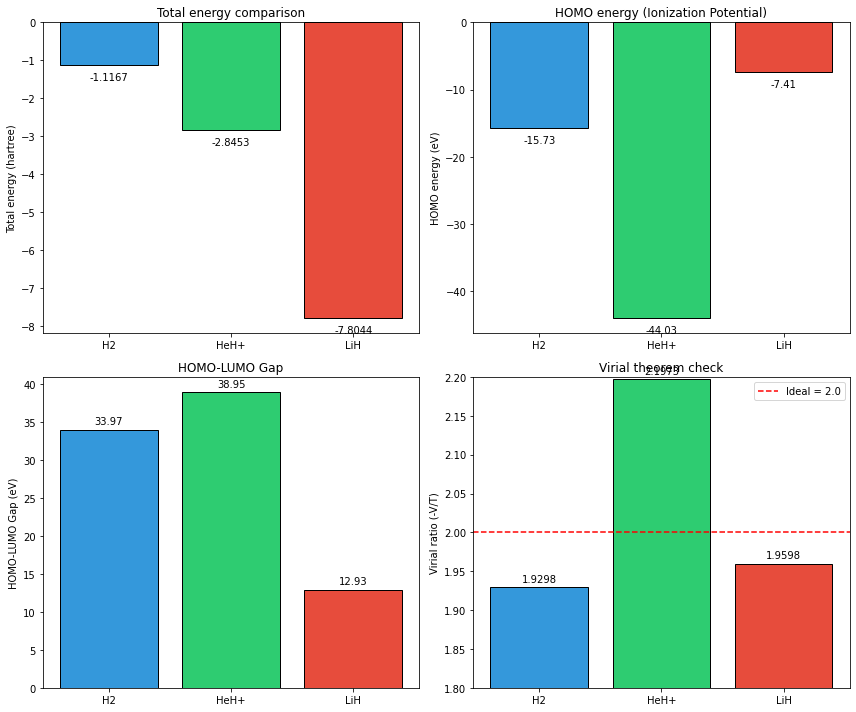

In [13]:
# Visualize comparison
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

names = list(results.keys())
colors = ['#3498db', '#2ecc71', '#e74c3c']

# Total energies
ax = axes[0, 0]
energies_list = [results[n]['energy'] for n in names]
bars = ax.bar(names, energies_list, color=colors, edgecolor='black')
ax.set_ylabel('Total energy (hartree)')
ax.set_title('Total energy comparison')
for bar, e in zip(bars, energies_list):
    ax.annotate(f'{e:.4f}', xy=(bar.get_x() + bar.get_width()/2, e),
               xytext=(0, -15), textcoords='offset points', ha='center', fontsize=10)

# HOMO energies
ax = axes[0, 1]
homos = [results[n]['homo'] for n in names]
homos_ev = [h * HARTREE_TO_EV for h in homos]
bars = ax.bar(names, homos_ev, color=colors, edgecolor='black')
ax.set_ylabel('HOMO energy (eV)')
ax.set_title('HOMO energy (Ionization Potential)')
for bar, e in zip(bars, homos_ev):
    ax.annotate(f'{e:.2f}', xy=(bar.get_x() + bar.get_width()/2, e),
               xytext=(0, -15), textcoords='offset points', ha='center', fontsize=10)

# HOMO-LUMO gaps
ax = axes[1, 0]
gaps = [results[n]['gap'] * HARTREE_TO_EV if results[n]['gap'] else 0 for n in names]
bars = ax.bar(names, gaps, color=colors, edgecolor='black')
ax.set_ylabel('HOMO-LUMO Gap (eV)')
ax.set_title('HOMO-LUMO Gap')
for bar, g in zip(bars, gaps):
    ax.annotate(f'{g:.2f}', xy=(bar.get_x() + bar.get_width()/2, g),
               xytext=(0, 5), textcoords='offset points', ha='center', fontsize=10)

# Virial ratios
ax = axes[1, 1]
virials = [results[n]['virial'] for n in names]
bars = ax.bar(names, virials, color=colors, edgecolor='black')
ax.axhline(y=2.0, color='red', linestyle='--', label='Ideal = 2.0')
ax.set_ylabel('Virial ratio (-V/T)')
ax.set_title('Virial theorem check')
ax.legend()
ax.set_ylim(1.8, 2.2)
for bar, v in zip(bars, virials):
    ax.annotate(f'{v:.4f}', xy=(bar.get_x() + bar.get_width()/2, v),
               xytext=(0, 5), textcoords='offset points', ha='center', fontsize=10)

plt.tight_layout()
plt.show()